# The Older Population: 2020 — Tables 3 and 4, with uncertainty

Census Brief [C2020BR-07](https://www2.census.gov/library/publications/decennial/2020/census-briefs/c2020br-07.pdf)
(Caplan and Rabe, May 2023) ranks counties by the share of their population aged 65 and over
(Table 3) and 85 and over (Table 4), listing the ten highest and the ten lowest of each.  Its
numbers are the published DHC tables: one post-processed value per cell, with no statement of
how far that value might be from the truth.

This notebook rebuilds both tables from the DHC **noisy measurement file** instead, and puts a
posterior around every number:

| column | where it comes from |
|---|---|
| Total population | the `pl94_con` constraint rows: the published PL94 table is an invariant of the DHC run, so county totals are **exact** |
| 65 years and over | `sex*age_18_64_116`: male and female 65–115 cells |
| 85 years and over | `sex*age_38_groups`: male and female 85–89, 90–94, …, 110–115 cells (12 noisy counts) |
| Percent | the age count divided by the exact total |
| Rank | the county's rank among all 3,143 counties in each joint posterior draw |

The brief's two **rural population** columns are not reproduced: urban/rural status is not an
axis of the DHC person histogram, so the NMF has no measurement of it.

**Data.**  The county-level DHC-P partitions for the 50 states and DC (about 5 GB), plus DC's
state-level partition (see below why).  Set `FETCH = True` below once, or call
`census.fetch_dhc(...)` yourself.  County names come from the 2020 Census Gazetteer county file,
downloaded and cached in `data/` on first run.

In [1]:
import io
import os
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)

from noisyvalue import census
from noisyvalue.census import dhc_2020
from noisyvalue.sample import sample_noisy_values

## Counties and their names

The DAS spine uses its own geocodes, but `dhc_2020` derives the standard five-digit county
GEOID for every county row, so the Gazetteer joins on that.  Puerto Rico is a separate NMF product
and is not part of the brief's county tables.

In [2]:
GAZ_URL = ("https://www2.census.gov/geo/docs/maps-data/data/gazetteer/"
           "2020_Gazetteer/2020_Gaz_counties_national.zip")
GAZ = Path("data/2020_Gaz_counties_national.txt")
if not GAZ.exists():
    with urllib.request.urlopen(GAZ_URL, timeout=60) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extract(GAZ.name, GAZ.parent)

gaz = pd.read_csv(GAZ, sep="\t", dtype=str).rename(columns=str.strip)
gaz = gaz[gaz.USPS != "PR"]

# full state names, from the census module's own lookup table
state_name = {fips: name.title().replace(" Of ", " of ")
              for name, fips in census._STATE_NAMES.items()}
counties = pd.DataFrame({
    "geoid": gaz.GEOID,
    "county": gaz.NAME + ", " + gaz.GEOID.str[:2].astype(int).map(state_name),
})
STATES = census.resolve_states(sorted(gaz.USPS.unique()))
print(len(counties), "counties in", len(STATES), "states and DC")

3143 counties in 51 states and DC


In [3]:
DC = 11
FETCH = False          # True mirrors any missing partitions from the Census S3 bucket
if FETCH:
    for fips in STATES:
        census.fetch_dhc("county", state=fips)
    census.fetch_dhc("state", state=DC)

## Exact totals

Each county's `pl94_con` row is the full published PL94 histogram for that area (8 hhgq × 2 voting
age × 2 Hispanic origin × 63 races), so its sum is the county's total population with no noise
at all.  The spine splits a state into a non-AIAN and an AIAN branch, so a county can have two
rows; they sum to the whole county.  A spine county geocode is a 3-digit branch-and-state code
followed by the county code, from which the standard GEOID follows (the same rule `census.py`
uses).

In [4]:
import polars as pl

def county_geoid(geocode):
    return f"{int(geocode[:3]) % 100:02d}{int(geocode[4:8]):03d}"

CONSTRAINTS = "data/2020-dhc-nmf-parquets/US_DHCP_PROD/County.parquet/Constraint/**/*.parquet"
con = (pl.scan_parquet(CONSTRAINTS, hive_partitioning=True)
         .filter(pl.col("query_name") == "pl94_con")
         .select("geocode", pl.col("value").list.sum().alias("total"))
         .collect())
totals = (pd.DataFrame({"geoid": [county_geoid(g) for g in con["geocode"]],
                        "total": con["total"].to_list()})
            .groupby("geoid")["total"].sum())
len(totals)

3143

## Posteriors for 65+ and 85+

One view per state, holding both queries.  Cells are conditioned on the NMF constraints
(`apply_constraints=True`) but **not truncated at zero one by one** (`nonnegative=False`); the
next section shows why.  For each county we sum its 65+ cells and its 85+ cells across sex and
spine branch, which gives a posterior centred on the noisy sum, and then impose what we know
about the *aggregates*: a flat prior on

$$0 \le \text{85+} \le \text{65+} \le \text{total population},$$

applied by rejection on the joint draws.  Counties whose noisy 85+ sum is near or below zero
accept only a fraction of draws, so they are resampled until each county has `N_DRAWS`
accepted draws.  Measurements in different counties are independent, so draws from separate
states can be stacked side by side.

**DC.**  The District is both a state and its own only county.  The DAS spent no budget on
its county level, so the release has DC county constraint rows but no county measurements;
the measurements of that same geography are at the state level, and are read from there.

In [5]:
AGE_65 = ["65-115"]
AGE_85 = ["85-89", "90-94", "95-99", "100-104", "105-109", "110-115"]
N_DRAWS = 4000
rng = np.random.default_rng(2020)

def truncated_draws(old, oldest, total, n, rng, max_rounds=500):
    # n joint draws per county of (65+, 85+), conditioned on 0 <= 85+ <= 65+ <= total
    k = len(old)
    out65, out85 = np.empty((k, n), np.int64), np.empty((k, n), np.int64)
    filled, tried = np.zeros(k, int), np.zeros(k, int)
    need = np.arange(k)
    for _ in range(max_rounds):
        if not len(need):
            return out65, out85, n / tried
        batches = sample_noisy_values(*old.iloc[need], *oldest.iloc[need], n=n, rng=rng)
        for j, i in enumerate(need):
            a, b = batches[j].draws, batches[len(need) + j].draws
            ok = (b >= 0) & (b <= a) & (a <= total[i])
            take = min(ok.sum(), n - filled[i])
            out65[i, filled[i]:filled[i] + take] = a[ok][:take]
            out85[i, filled[i]:filled[i] + take] = b[ok][:take]
            filled[i] += take
            tried[i] += n
        need = np.flatnonzero(filled < n)
    raise RuntimeError(f"{len(need)} counties never reached {n} accepted draws")

def noisy_sums(frame, ages):
    # one noisy sum per county, carrying every summed cell's posterior
    return frame[frame.age.isin(ages)].groupby("geoid")["value"].sum()

geo, d65, d85 = [], [], []
for fips in STATES:
    level = "state" if fips == DC else "county"
    view = dhc_2020.view(level, state=fips, nonnegative=False)
    broad = view.query("sex*age_18_64_116")
    fine = view.query("sex*age_38_groups")
    if fips == DC:
        broad, fine = broad.assign(geoid="11001"), fine.assign(geoid="11001")

    old = noisy_sums(broad, AGE_65)
    oldest = noisy_sums(fine, AGE_85).loc[old.index]
    total = totals.loc[old.index].to_numpy()

    a, b, accept = truncated_draws(old, oldest, total, N_DRAWS, rng)
    d65.append(a)
    d85.append(b)
    geo.append(pd.DataFrame({"geoid": old.index, "total": total,
                             "obs65": [float(v) for v in old],
                             "obs85": [float(v) for v in oldest],
                             "accept": accept}))

geo = pd.concat(geo, ignore_index=True).merge(counties, on="geoid", how="left")
draws65, draws85 = np.vstack(d65), np.vstack(d85)
assert geo.county.notna().all() and geo.total.notna().all()
print(len(geo), "counties;", draws65.shape[1], "draws each")

3143 counties; 4000 draws each


## Summaries and ranks

For each county: the posterior median and 95% equal-tailed interval of the count and of the
percent, and the distribution of its rank among all counties (1 = highest percentage).  Ranks
are computed draw by draw, so they carry the joint uncertainty of every county at once; ties
(common among tiny counties at 0 people aged 85+) are broken at random.

In [6]:
def summarize(draws, total, top=10):
    pct = 100 * draws / total[:, None]
    jitter = rng.uniform(0, 1e-9, size=pct.shape)
    rank = (-(pct + jitter)).argsort(axis=0).argsort(axis=0) + 1
    n = len(total)
    q = lambda x: np.percentile(x, [2.5, 50, 97.5], axis=1)
    (n_lo, n_md, n_hi), (p_lo, p_md, p_hi), (r_lo, _, r_hi) = q(draws), q(pct), q(rank)
    return pd.DataFrame({
        "n": n_md, "n_lo": n_lo, "n_hi": n_hi,
        "pct": p_md, "pct_lo": p_lo, "pct_hi": p_hi, "pct_mean": pct.mean(axis=1),
        "rank_lo": r_lo, "rank_hi": r_hi,                       # 1 = highest
        "p_top": (rank <= top).mean(axis=1),
        "p_bottom": (rank > n - top).mean(axis=1),
    })

total = geo.total.to_numpy().astype(float)
post65 = pd.concat([geo, summarize(draws65, total)], axis=1)
post85 = pd.concat([geo, summarize(draws85, total)], axis=1)

## The brief's published values

Transcribed from Tables 3 and 4 of the brief (published DHC values; rural columns omitted).

In [7]:
BRIEF = pd.read_csv(io.StringIO('''table,panel,county,total,number
65,high,"Sumter County, Florida",129752,76372
65,high,"Catron County, New Mexico",3579,1551
65,high,"Charlotte County, Florida",186847,75400
65,high,"Jefferson County, Washington",32977,12851
65,high,"Lancaster County, Virginia",10919,4192
65,high,"Harding County, New Mexico",657,251
65,high,"Sarasota County, Florida",434006,163151
65,high,"Northumberland County, Virginia",11839,4448
65,high,"McCormick County, South Carolina",9526,3568
65,high,"Citrus County, Florida",153843,57403
65,low,"Utah County, Utah",659399,53593
65,low,"Manassas Park city, Virginia",17219,1343
65,low,"Oglala Lakota County, South Dakota",13672,1029
65,low,"Northwest Arctic Borough, Alaska",7793,576
65,low,"Aleutians East Borough, Alaska",3420,235
65,low,"Kusilvak Census Area, Alaska",8368,540
65,low,"Madison County, Idaho",52913,3238
65,low,"North Slope Borough, Alaska",11031,675
65,low,"Aleutians West Census Area, Alaska",5232,303
65,low,"Chattahoochee County, Georgia",9565,459
85,high,"McIntosh County, North Dakota",2530,208
85,high,"Kalawao County, Hawaii",82,6
85,high,"Petroleum County, Montana",496,35
85,high,"Kent County, Texas",753,46
85,high,"Wibaux County, Montana",937,56
85,high,"McPherson County, South Dakota",2411,143
85,high,"Hyde County, South Dakota",1262,72
85,high,"Nelson County, North Dakota",3015,172
85,high,"Faulk County, South Dakota",2125,121
85,high,"Harding County, New Mexico",657,37
85,low,"Oglala Lakota County, South Dakota",13672,66
85,low,"Lake and Peninsula Borough, Alaska",1476,7
85,low,"Nome Census Area, Alaska",10046,47
85,low,"Bethel Census Area, Alaska",18666,84
85,low,"Kusilvak Census Area, Alaska",8368,36
85,low,"Ziebach County, South Dakota",2413,10
85,low,"Aleutians West Census Area, Alaska",5232,19
85,low,"North Slope Borough, Alaska",11031,39
85,low,"Summit County, Colorado",31055,97
85,low,"Aleutians East Borough, Alaska",3420,7
'''))
BRIEF["pct"] = 100 * BRIEF.number / BRIEF.total

check = BRIEF.drop_duplicates("county").merge(geo[["county", "total"]], on="county",
                                               suffixes=("_brief", "_nmf"))
assert len(check) == BRIEF.county.nunique()
print("total population matches the brief for",
      (check.total_brief == check.total_nmf).sum(), "of", len(check), "counties")

total population matches the brief for 34 of 34 counties


The exact totals agree with the brief to the person, as they should: both are the published PL94
counts.  Everything else below is a posterior.

## Why the cells are not truncated one by one

The library's default (`nonnegative=True`) gives every cell a flat prior on the nonnegative
integers.  That is harmless for one cell, but a sum of *k* such cells inherits a prior density
proportional to $s^{k-1}$, which pulls hard towards large totals.  85+ is a sum of 12 cells
(24 where the county has an AIAN spine branch, as most of Alaska does), half of them for ages
100+ where the true counts are essentially zero.  Here is what each choice gives for counties in
the brief's Table 4:

In [8]:
demo = ["02164", "02013", "02016", "02180", "02050", "38051", "15005"]
published = BRIEF[BRIEF.table == 85].set_index("county").number
rows = []
for fips in sorted({int(g[:2]) for g in demo}):
    fine = dhc_2020.view("county", state=fips).query("sex*age_38_groups")   # nonnegative=True
    cellwise = noisy_sums(fine, AGE_85)
    for g in (g for g in demo if int(g[:2]) == fips):
        i = geo.index[geo.geoid == g][0]
        d = sample_noisy_values(cellwise[g], n=N_DRAWS, rng=rng)[0].draws
        rows.append({
            "County": geo.county[i],
            "85+ cells": int((fine.geoid.eq(g) & fine.age.isin(AGE_85)).sum()),
            "Noisy sum": geo.obs85[i],
            "Per-cell truncation: mean": d.mean(),
            "Aggregate truncation: mean": draws85[i].mean(),
            "Aggregate: 95% interval": "{:.0f}–{:.0f}".format(*np.percentile(draws85[i], [2.5, 97.5])),
            "Published": published.get(geo.county[i]),
        })
pd.DataFrame(rows).round(1)

,County,85+ cells,Noisy sum,Per-cell truncation: mean,Aggregate truncation: mean,Aggregate: 95% interval,Published
0,"Lake and Peninsula Borough, Alaska",24,59.0,133.2,60.9,12–114,7
1,"Aleutians East Borough, Alaska",24,17.0,132.9,29.2,1–75,7
2,"Aleutians West Census Area, Alaska",24,-30.0,106.9,13.7,0–44,19
3,"Nome Census Area, Alaska",24,63.0,149.9,63.2,13–116,47
4,"Bethel Census Area, Alaska",24,97.0,165.5,97.1,55–141,84
5,"Kalawao County, Hawaii",24,17.0,29.0,12.2,1–24,6
6,"McIntosh County, North Dakota",12,195.0,237.0,194.5,157–233,208


Per-cell truncation adds roughly 4–5 people per near-empty cell, so with 24 cells, counties with
a published 85+ count of 7 come out above 100.  Truncating the aggregate keeps the posterior
centred on the measurement.  The price is honesty about the noise: 24 cells of variance 32.3
give the sum a standard deviation of about 28 people, which is larger than the published 85+
count of most of the counties on the brief's "lowest" list.

In [9]:
def fmt_count(m, lo, hi):
    return f"{m:,.0f} ({lo:,.0f}–{hi:,.0f})"

def fmt_pct(m, lo, hi):
    return f"{m:.1f} ({lo:.1f}–{hi:.1f})"

def table(post, age, panel, top=10):
    n = len(post)
    if panel == "high":
        rows = post.sort_values(["pct", "pct_mean"], ascending=False).head(top)
        rank = lambda r: (r.rank_lo, r.rank_hi)
        prob = rows.p_top
    else:
        rows = post.sort_values(["pct", "pct_mean"]).head(top)
        rank = lambda r: (n + 1 - r.rank_hi, n + 1 - r.rank_lo)   # 1 = lowest
        prob = rows.p_bottom
    brief = BRIEF[BRIEF.table == age].set_index("county")
    listed = set(BRIEF[(BRIEF.table == age) & (BRIEF.panel == panel)].county)
    return pd.DataFrame({
        "County": rows.county,
        "Total population": rows.total.map("{:,}".format),
        f"{age}+ number": [fmt_count(*v) for v in zip(rows.n, rows.n_lo, rows.n_hi)],
        f"{age}+ percent": [fmt_pct(*v) for v in zip(rows.pct, rows.pct_lo, rows.pct_hi)],
        "Rank (95%)": ["{:.0f}–{:.0f}".format(*rank(r)) for r in rows.itertuples()],
        f"P({'top' if panel == 'high' else 'bottom'} 10)": prob.map("{:.2f}".format),
        "Brief percent": [f"{brief.pct[c]:.1f}" if c in brief.index else "" for c in rows.county],
        "In brief's list": ["yes" if c in listed else "no" for c in rows.county],
    }).reset_index(drop=True).set_index(pd.RangeIndex(1, top + 1))

## Table 3. Ten counties with the highest and lowest percentage of their population 65 years and over

Counties are ordered by posterior median percentage.  Numbers are posterior medians with 95%
intervals in parentheses; *Rank (95%)* is the 95% interval of the county's rank (from the top in
the first panel, from the bottom in the second).

In [10]:
print("Highest percentage 65 years and over")
display(table(post65, 65, "high"))
print("Lowest percentage 65 years and over")
display(table(post65, 65, "low"))

Highest percentage 65 years and over


,County,Total population,65+ number,65+ percent,Rank (95%),P(top 10),Brief percent,In brief's list
1,"Sumter County, Florida","129,752","76,369 (76,353–76,385)",58.9 (58.8–58.9),1–1,1.00,58.9,yes
2,"Catron County, New Mexico","3,579","1,554 (1,538–1,570)",43.4 (43.0–43.9),2–2,1.00,43.3,yes
3,"Charlotte County, Florida","186,847","75,414 (75,398–75,429)",40.4 (40.4–40.4),3–4,1.00,40.4,yes
4,"Jefferson County, Washington","32,977","12,857 (12,840–12,873)",39.0 (38.9–39.0),4–5,1.00,39.0,yes
5,"Lancaster County, Virginia","10,919","4,215 (4,200–4,231)",38.6 (38.5–38.7),5–6,1.00,38.4,yes
6,"Harding County, New Mexico",657,252 (236–267),38.4 (35.9–40.6),3–14,0.87,38.2,yes
7,"Northumberland County, Virginia","11,839","4,464 (4,448–4,480)",37.7 (37.6–37.8),6–8,1.00,37.6,yes
8,"Sarasota County, Florida","434,006","163,159 (163,143–163,174)",37.6 (37.6–37.6),7–8,1.00,37.6,yes
9,"McCormick County, South Carolina","9,526","3,561 (3,545–3,577)",37.4 (37.2–37.5),8–10,0.99,37.5,yes
10,"Citrus County, Florida","153,843","57,420 (57,404–57,436)",37.3 (37.3–37.3),8–10,0.98,37.3,yes


Lowest percentage 65 years and over


,County,Total population,65+ number,65+ percent,Rank (95%),P(bottom 10),Brief percent,In brief's list
1,"Chattahoochee County, Georgia","9,565",453 (445–461),4.7 (4.7–4.8),1–1,1.00,4.8,yes
2,"Aleutians West Census Area, Alaska","5,232",293 (271–315),5.6 (5.2–6.0),2–3,1.00,5.8,yes
3,"North Slope Borough, Alaska","11,031",660 (642–677),6.0 (5.8–6.1),2–5,1.00,6.1,yes
4,"Madison County, Idaho","52,913","3,218 (3,202–3,234)",6.1 (6.1–6.1),3–5,1.00,6.1,yes
5,"Aleutians East Borough, Alaska","3,420",216 (194–238),6.3 (5.7–7.0),2–6,1.00,6.9,yes
6,"Kusilvak Census Area, Alaska","8,368",533 (516–550),6.4 (6.2–6.6),5–6,1.00,6.5,yes
7,"Oglala Lakota County, South Dakota","13,672","1,029 (1,013–1,045)",7.5 (7.4–7.6),7–8,1.00,7.5,yes
8,"Northwest Arctic Borough, Alaska","7,793",590 (573–607),7.6 (7.4–7.8),7–9,1.00,7.4,yes
9,"Manassas Park city, Virginia","17,219","1,340 (1,332–1,349)",7.8 (7.7–7.8),8–9,1.00,7.8,yes
10,"Utah County, Utah","659,399","53,609 (53,593–53,625)",8.1 (8.1–8.1),10–11,0.87,8.1,yes


## Table 4. Ten counties with the highest and lowest percentage of their population 85 years and over

In [11]:
print("Highest percentage 85 years and over")
display(table(post85, 85, "high"))
print("Lowest percentage 85 years and over")
display(table(post85, 85, "low"))

Highest percentage 85 years and over


,County,Total population,85+ number,85+ percent,Rank (95%),P(top 10),Brief percent,In brief's list
1,"Kalawao County, Hawaii",82,12 (1–24),14.6 (1.2–29.3),1–2928,0.82,7.3,yes
2,"Harding County, New Mexico",657,55 (17–93),8.4 (2.6–14.2),1–796,0.68,5.6,yes
3,"Petroleum County, Montana",496,39 (5–76),7.9 (1.0–15.3),1–3016,0.60,7.1,yes
4,"McIntosh County, North Dakota","2,530",194 (157–233),7.7 (6.2–9.2),3–19,0.79,8.2,yes
5,"Kent County, Texas",753,56 (18–95),7.4 (2.4–12.6),2–1095,0.55,6.1,yes
6,"Arthur County, Nebraska",434,32 (3–68),7.4 (0.7–15.7),1–3103,0.53,,no
7,"Faulk County, South Dakota","2,125",156 (116–195),7.3 (5.5–9.2),3–31,0.62,5.7,yes
8,"Wibaux County, Montana",937,68 (29–106),7.3 (3.1–11.3),2–405,0.54,6.0,yes
9,"Greeley County, Kansas","1,284",89 (51–127),6.9 (4.0–9.9),3–130,0.49,,no
10,"Daniels County, Montana","1,661",107 (65–147),6.4 (3.9–8.9),4–137,0.31,,no


Lowest percentage 85 years and over


,County,Total population,85+ number,85+ percent,Rank (95%),P(bottom 10),Brief percent,In brief's list
1,"Aleutians West Census Area, Alaska","5,232",10 (0–44),0.2 (0.0–0.8),1–65,0.61,0.4,yes
2,"Summit County, Colorado","31,055",79 (42–119),0.3 (0.1–0.4),4–18,0.58,0.3,yes
3,"Dallam County, Texas","7,115",24 (2–60),0.3 (0.0–0.8),2–64,0.38,,no
4,"North Slope Borough, Alaska","11,031",39 (4–81),0.4 (0.0–0.7),2–44,0.33,0.4,yes
5,"Ziebach County, South Dakota","2,413",10 (0–37),0.4 (0.0–1.5),1–537,0.36,0.4,yes
6,"Kusilvak Census Area, Alaska","8,368",36 (4–77),0.4 (0.0–0.9),3–85,0.24,0.4,yes
7,"Kodiak Island Borough, Alaska","13,101",61 (13–117),0.5 (0.1–0.9),4–77,0.17,,no
8,"Prince of Wales-Hyder Census Area, Alaska","5,753",28 (1–78),0.5 (0.0–1.4),2–327,0.28,,no
9,"Chattahoochee County, Georgia","9,565",47 (26–68),0.5 (0.3–0.7),10–43,0.03,,no
10,"Eagle County, Colorado","55,731",276 (238–316),0.5 (0.4–0.6),15–32,0.00,,no


## Reading the results

**Table 3 holds up.**  Both lists name the same ten counties as the brief, and every one of them
has at least an 0.87 posterior probability of belonging there.  The 65+ counts are measured to
within about ±16 people (±22 where a county also has an AIAN spine branch), so percentages are pinned to a tenth of a point except in the smallest
counties: Harding County, New Mexico (657 people) is 38.4% (35.9–40.6) and could rank anywhere
from 3rd to 14th.

**Table 4 mostly does not.**  The 85+ count is a sum of 12 or 24 noisy cells, so its 95% interval
is about ±40 people (±55 with an AIAN branch) whatever the county's size, and the extreme percentages belong to
counties with a few hundred to a few thousand residents.  Only 7 of the brief's ten "highest"
counties and 5 of its ten "lowest" are in this notebook's ten; the brief's own counties have
posterior probabilities between about 0.01 and 0.8 of being on their lists.  Kalawao County, Hawaii (82
residents) could rank anywhere from 1st to roughly 2,900th.  The data support statements like
"McIntosh County, North Dakota is among the oldest-old counties" (7.7%, 6.2–9.2), but not a ranked
top ten.

The figures quoted here are Monte Carlo estimates from 4,000 draws, so a rerun can move an interval endpoint by a person or swap the borderline tenth county on an 85+ list.

## The brief's counties against their posteriors

For every county the brief lists: its published count and percentage, the 95% posterior interval
for each, and the posterior probability that it belongs on the list it appears on.  The published
values are the TopDown Algorithm's post-processed output, which drew on measurements at every
geographic level, so they are a different estimate of the same truth rather than the truth
itself; landing outside the interval is a disagreement between two estimates, not an error in
either.

In [12]:
def against_brief(post, age):
    rows = BRIEF[BRIEF.table == age].merge(post, on="county", suffixes=("_brief", ""))
    prob = np.where(rows.panel == "high", rows.p_top, rows.p_bottom)
    return pd.DataFrame({
        "List": rows.panel,
        "County": rows.county,
        "Published number": rows.number.map("{:,}".format),
        "Posterior number (95%)": [fmt_count(*v) for v in zip(rows.n, rows.n_lo, rows.n_hi)],
        "Inside": np.where((rows.n_lo <= rows.number) & (rows.number <= rows.n_hi), "yes", "no"),
        "Published %": rows.pct_brief.map("{:.1f}".format),
        "Posterior % (95%)": [fmt_pct(*v) for v in zip(rows.pct, rows.pct_lo, rows.pct_hi)],
        "P(on this list)": pd.Series(prob).map("{:.2f}".format),
    })

cmp65, cmp85 = against_brief(post65, 65), against_brief(post85, 85)
for age, cmp in ((65, cmp65), (85, cmp85)):
    print(f"{age}+: published number inside the 95% interval for "
          f"{(cmp.Inside == 'yes').sum()} of {len(cmp)} counties")
display(cmp65)
display(cmp85)

65+: published number inside the 95% interval for 17 of 20 counties
85+: published number inside the 95% interval for 19 of 20 counties


,List,County,Published number,Posterior number (95%),Inside,Published %,Posterior % (95%),P(on this list)
0,high,"Sumter County, Florida","76,372","76,369 (76,353–76,385)",yes,58.9,58.9 (58.8–58.9),1.00
1,high,"Catron County, New Mexico","1,551","1,554 (1,538–1,570)",yes,43.3,43.4 (43.0–43.9),1.00
2,high,"Charlotte County, Florida","75,400","75,414 (75,398–75,429)",yes,40.4,40.4 (40.4–40.4),1.00
3,high,"Jefferson County, Washington","12,851","12,857 (12,840–12,873)",yes,39.0,39.0 (38.9–39.0),1.00
4,high,"Lancaster County, Virginia","4,192","4,215 (4,200–4,231)",no,38.4,38.6 (38.5–38.7),1.00
5,high,"Harding County, New Mexico",251,252 (236–267),yes,38.2,38.4 (35.9–40.6),0.87
6,high,"Sarasota County, Florida","163,151","163,159 (163,143–163,174)",yes,37.6,37.6 (37.6–37.6),1.00
7,high,"Northumberland County, Virginia","4,448","4,464 (4,448–4,480)",yes,37.6,37.7 (37.6–37.8),1.00
8,high,"McCormick County, South Carolina","3,568","3,561 (3,545–3,577)",yes,37.5,37.4 (37.2–37.5),0.99
9,high,"Citrus County, Florida","57,403","57,420 (57,404–57,436)",no,37.3,37.3 (37.3–37.3),0.98


,List,County,Published number,Posterior number (95%),Inside,Published %,Posterior % (95%),P(on this list)
0,high,"McIntosh County, North Dakota",208,194 (157–233),yes,8.2,7.7 (6.2–9.2),0.79
1,high,"Kalawao County, Hawaii",6,12 (1–24),yes,7.3,14.6 (1.2–29.3),0.82
2,high,"Petroleum County, Montana",35,39 (5–76),yes,7.1,7.9 (1.0–15.3),0.60
3,high,"Kent County, Texas",46,56 (18–95),yes,6.1,7.4 (2.4–12.6),0.55
4,high,"Wibaux County, Montana",56,68 (29–106),yes,6.0,7.3 (3.1–11.3),0.54
5,high,"McPherson County, South Dakota",143,152 (114–191),yes,5.9,6.3 (4.7–7.9),0.19
6,high,"Hyde County, South Dakota",72,80 (39–121),yes,5.7,6.3 (3.1–9.6),0.35
7,high,"Nelson County, North Dakota",172,158 (117–200),yes,5.7,5.2 (3.9–6.6),0.01
8,high,"Faulk County, South Dakota",121,156 (116–195),yes,5.7,7.3 (5.5–9.2),0.62
9,high,"Harding County, New Mexico",37,55 (17–93),yes,5.6,8.4 (2.6–14.2),0.68


## Picture

Each panel shows the union of this notebook's ten and the brief's ten for one list: the posterior
median and 95% interval of the percentage in blue, the brief's published percentage as a hollow
orange diamond where the county is on the brief's list.  Most 65+ intervals are narrower than
the dot.

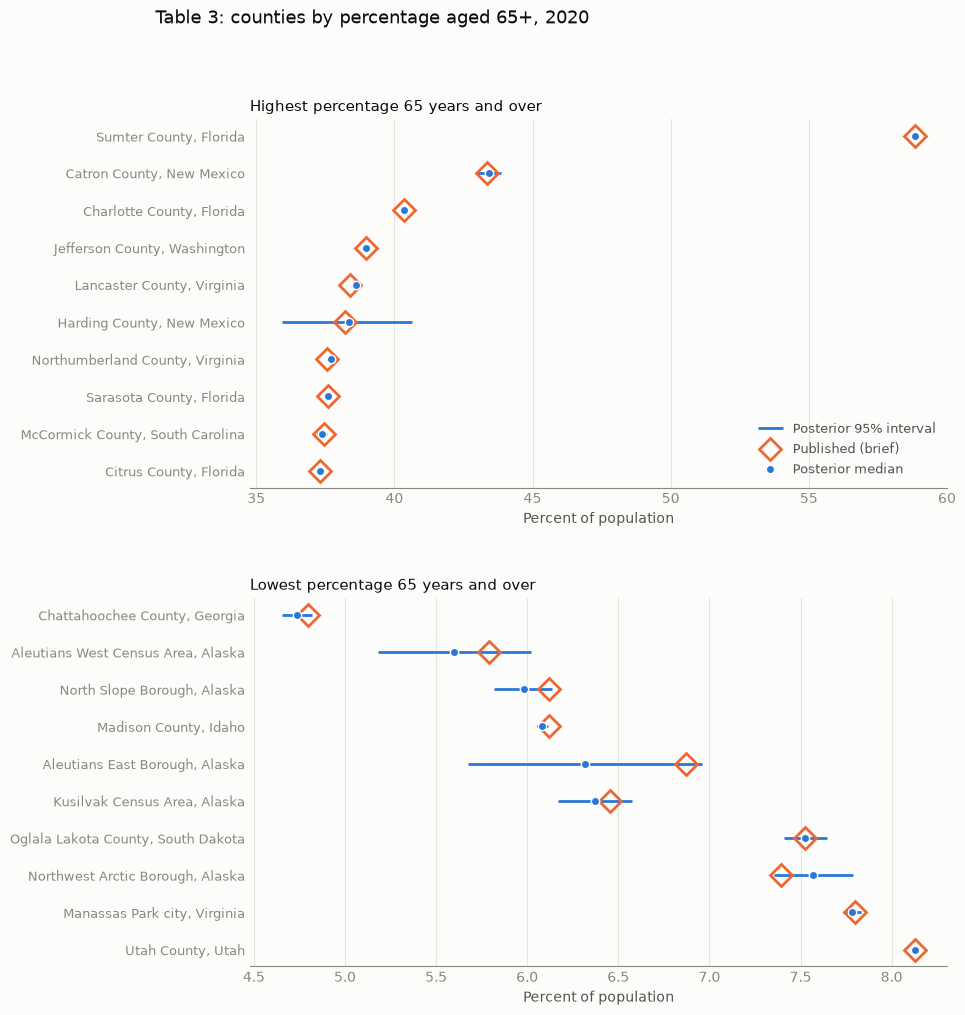

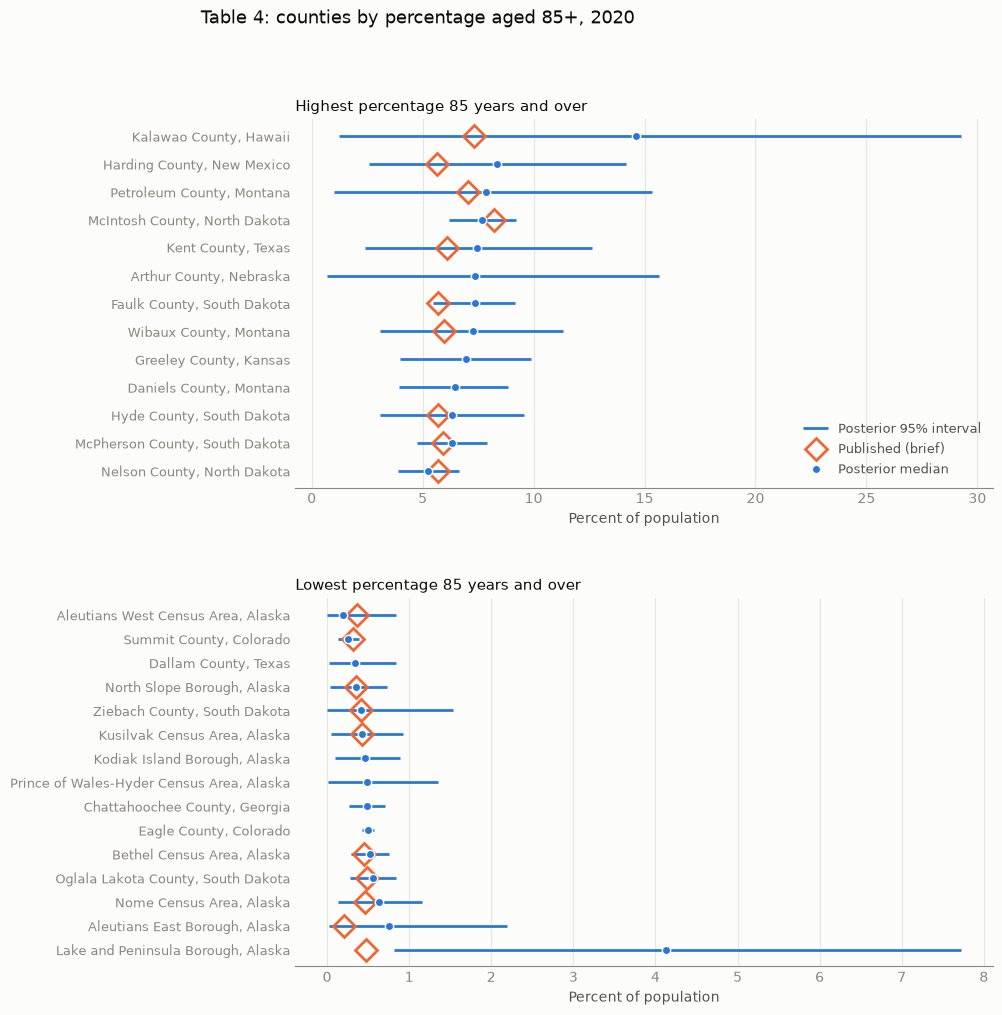

In [13]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"

def candidates(post, age, panel, top=10):
    ours = (post.sort_values(["pct", "pct_mean"], ascending=(panel == "low"))
                .head(top).county)
    theirs = BRIEF[(BRIEF.table == age) & (BRIEF.panel == panel)].county
    rows = post[post.county.isin(set(ours) | set(theirs))]
    brief = BRIEF[BRIEF.table == age].set_index("county").pct
    # rank 1 of each list at the top of its panel
    return (rows.assign(brief=rows.county.map(brief))
                .sort_values("pct", ascending=(panel == "high")))

def interval_panel(ax, rows, title):
    y = np.arange(len(rows))
    ax.hlines(y, rows.pct_lo, rows.pct_hi, color=BLUE, lw=2, label="Posterior 95% interval")
    # hollow published marker under the posterior dot, so a match shows both
    ax.plot(rows.brief, y, "D", ms=11, mfc="none", mec=ORANGE, mew=2,
            label="Published (brief)", zorder=2)
    ax.plot(rows.pct, y, "o", color=BLUE, ms=6, mec=SURFACE, mew=1, label="Posterior median",
            zorder=3)
    ax.set_yticks(y, rows.county, fontsize=9, color=INK2)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Percent of population", color=INK2)
    ax.grid(axis="x", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(MUTED)
    ax.set_facecolor(SURFACE)

for age, post in ((65, post65), (85, post85)):
    fig, axes = plt.subplots(2, 1, figsize=(9, 11), facecolor=SURFACE,
                             gridspec_kw={"hspace": 0.3})
    for ax, panel, word in zip(axes, ("high", "low"), ("Highest", "Lowest")):
        interval_panel(ax, candidates(post, age, panel),
                       f"{word} percentage {age} years and over")
    axes[0].legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK2)
    fig.suptitle(f"Table {3 if age == 65 else 4}: counties by percentage aged {age}+, 2020",
                 x=0.02, ha="left", fontsize=13, color=INK)
    plt.show()

## Notes

- **What the intervals mean.**  Each is a posterior for the true 2020 count given only the
  county-level noisy measurements, the NMF constraints (the exact PL94 table for the county, the
  relgq age rules, the GQ bounds), and a flat prior on the aggregates restricted to
  0 ≤ 85+ ≤ 65+ ≤ total.  State and national measurements, which TopDown also used, do not
  inform these posteriors.
- **65+ intervals are somewhat conservative.**  The PL94 invariant pins each county's
  voting-age total, which ties the four adult cells (male/female × 18–64/65+) to a known sum.
  The framework treats a constraint block with three or more free cells as an upper bound only
  (see `dataset/solve.py`), so it does not use that equality.  Exact Gaussian conditioning on it
  would shrink the 65+ standard deviation by about √2.  A second, independent measurement of
  65+ is also left unused: `relgq_4_groups*age_18_64_116` measures it again via four cells, and
  precision-weighting the two would shrink it further.
- **85+ is the weak column.**  No released DHC query has a single 85+ cell; the narrowest is
  six age bins × two sexes.  For a county of a few thousand people the 85+ percentage is
  identified only to within a few points, so the brief's "lowest percentage 85 years and over"
  list in particular is mostly noise as far as these measurements can tell.  `geo.accept`
  records the share of draws that satisfied the aggregate bounds; it is far below 1 only where
  the noisy 85+ sum itself was near or below zero.
- **Ranks.**  A county's place on a "ten highest" list depends on every other county's noise
  too, which is what the rank interval and P(top 10) capture.  Neither the brief's list nor
  ours is the list; the probabilities say how settled each membership is.
- **Rural columns** cannot be reproduced from the NMF; urban/rural is not a DHC-P axis.